In [22]:
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

In [23]:
shots_map_df = pd.read_csv('../../data/raw/nba-api/shots_2025-26.csv')
defense_df = pd.read_csv('../../data/raw/nba-api/synergy_defense_2025-26.csv')
offense_df = pd.read_csv('../../data/raw/nba-api/synergy_offense_2025-26.csv')

In [24]:
ks = range(2, 13)
inertias, sils = [], []

poss = defense_df.pivot_table(index='PLAYER_NAME', columns='PLAY_TYPE', values='POSS',
                              aggfunc='sum', fill_value=0)
defense_freq = poss.div(poss.sum(axis=1), axis=0)
defense_freq = defense_freq[poss.sum(axis=1) >= 75]

print(poss)

for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(defense_freq)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(defense_freq, km.labels_))

# By whoever ended the play- so these values are going to be a little weird. (Zach Edey ends up
# guarding a lot of ball handlers even though hes a center due to mismatch)

PLAY_TYPE        Handoff  Isolation  OffScreen  PRBallHandler  PRRollMan  \
PLAYER_NAME                                                                
AJ Green              36         62         29            200         57   
AJ Johnson             0          0          0             19          0   
Aaron Gordon          20         39         18            111         30   
Aaron Holiday         22         19         19            108         28   
Aaron Nesmith         54         35         36            170         32   
...                  ...        ...        ...            ...        ...   
Zach Edey              0          0          0             71         13   
Zach LaVine           28         22         14            120         35   
Zeke Nnaji             0         30          0            112         25   
Ziaire Williams       24         47         32            130         55   
Zion Williamson       21         85         28            190         48   

PLAY_TYPE  

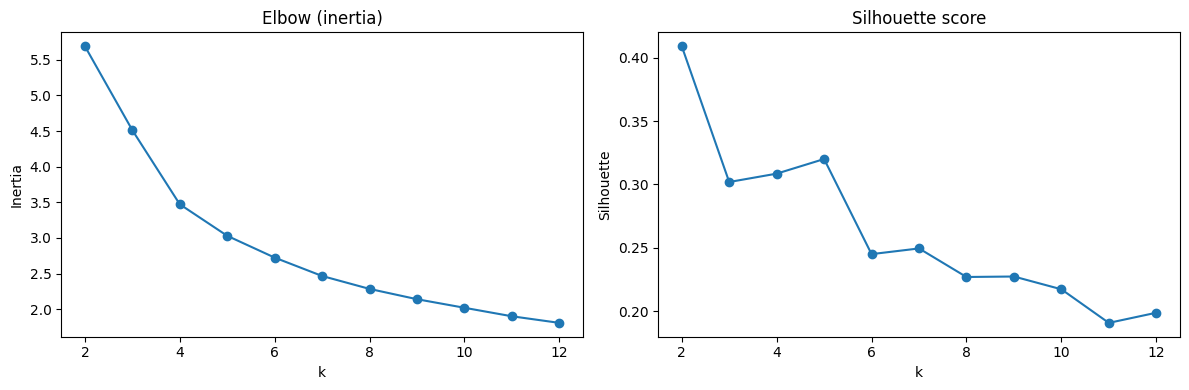

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(ks, inertias, marker='o')
ax[0].set_title('Elbow (inertia)')
ax[0].set_xlabel('k')
ax[0].set_ylabel('Inertia')

ax[1].plot(ks, sils, marker='o')
ax[1].set_title('Silhouette score')
ax[1].set_xlabel('k')
ax[1].set_ylabel('Silhouette')

plt.tight_layout()
plt.show()


PLAY_TYPE,Handoff,Isolation,OffScreen,PRBallHandler,PRRollMan,Postup,Spotup,n_players
0,0.00,0.09,0.01,0.51,0.15,0.03,0.22,75
1,0.05,0.10,0.04,0.31,0.08,0.04,0.38,161
2,0.14,0.23,0.12,0.00,0.39,0.13,0.00,3
3,0.07,0.09,0.06,0.38,0.08,0.04,0.28,158
4,0.14,0.10,0.11,0.00,0.12,0.08,0.44,4


0 ['Adem Bona', 'Al Horford', 'Alex Sarr', 'Alperen Sengun', 'Andre Drummond', 'Anthony Davis', 'Anthony Gill', 'Bam Adebayo', 'Bobby Portis Jr.', 'Branden Carlson']
1 ['AJ Green', 'Aaron Gordon', 'Aaron Wiggins', 'Ace Bailey', 'Alex Caruso', 'Andrew Wiggins', 'Anfernee Simons', 'Anthony Edwards', 'Asa Newell', 'Ayo Dosunmu']
2 ['Clint Capela', 'Precious Achiuwa', 'Russell Westbrook']
3 ['Aaron Holiday', 'Aaron Nesmith', 'Ajay Mitchell', 'Amen Thompson', 'Andrew Nembhard', 'Anthony Black', 'Ausar Thompson', 'Austin Reaves', 'Baylor Scheierman', 'Ben Sheppard']
4 ['CJ McCollum', 'Jamir Watkins', 'Tre Johnson', 'Will Riley']


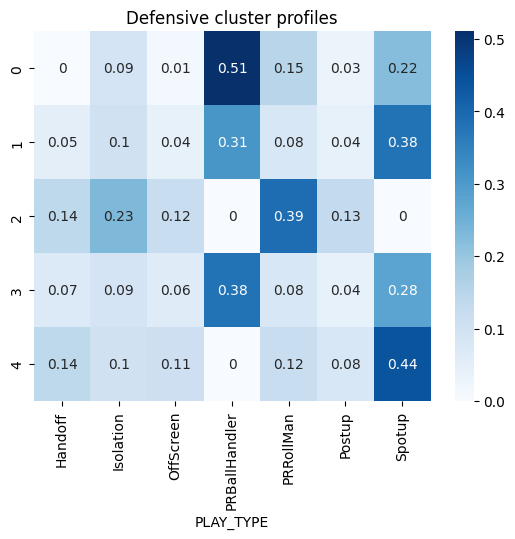

In [26]:
km = KMeans(n_clusters=5, n_init=20, random_state=42).fit(defense_freq)
defense_freq['Cluster'] = km.labels_

# What each cluster guards (average share per play type)
centers = pd.DataFrame(km.cluster_centers_, columns=defense_freq.columns.drop('Cluster')).round(2)
centers['n_players'] = defense_freq['Cluster'].value_counts().sort_index()
display(centers)

# Who's in each cluster
for c, grp in defense_freq.groupby('Cluster'):
    print(c, grp.index[:10].tolist())

sns.heatmap(centers.drop(columns='n_players'), annot=True, cmap='Blues')
plt.title('Defensive cluster profiles')
plt.show()

# I wonder if this chart more or less gives a good understanding of nba is constantly hunting for mismatches